IMPORTS

In [172]:

import pandas as pd
import numpy as np
import re

from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

import shap
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler


Load Dataset

In [173]:

df = pd.read_csv("composites.csv")


Filtering 

In [174]:
df = df[df["measurement_type"].str.lower() == "electrode"]

df = df[df["test_mode"].str.lower().str.contains("gcd", na=False)]
df = df[df["current_density_value"].notna()]

df = df[df["current_density_unit"].str.lower().str.contains(r"ma/g|a/g", na=False)]
df = df[df["capacitance_unit"].str.lower().str.contains(r"f/g|mf/g", na=False)]

print("After filtering:", len(df))


After filtering: 549


Unit Standardization

In [175]:

def convert_current_density(val, unit):
    if pd.isna(val): return val 
    unit = str(unit).lower()
    if "ma" in unit: return val / 1000
    elif "a" in unit: return val
    else: return np.nan

def convert_capacitance(val, unit):
    if pd.isna(val): return val
    unit = str(unit).lower()
    if "mf" in unit: return val / 1000
    elif "f" in unit: return val
    else: return np.nan

if "current_density_unit" in df.columns:
    df["current_density_value"] = df.apply(
        lambda x: convert_current_density(x["current_density_value"], x["current_density_unit"]), axis=1
    )

if "capacitance_unit" in df.columns:
    df["specific_capacitance"] = df.apply(
        lambda x: convert_capacitance(x["specific_capacitance"], x["capacitance_unit"]), axis=1
    )


Numeric cleaning

In [176]:

numeric_cols = [
    "specific_surface_area_m2g","pore_volume_cm3g","average_pore_size_nm","ID_IG_ratio",
    "carbonization_temperature_C","activation_temperature_C","activation_ratio",
    "calcination_temperature_C","current_density_value","potential_window_V",
    "electrolyte_concentration_M","Rct_ohms","Rs_ohms","mass_loading_mgcm2","metal_loading_wt_percent"
]

def parse_range(x):
    if isinstance(x, str):#check if a value is a string 
        nums = re.findall(r"\d+\.?\d*", x)
        if len(nums) == 2:#if range take average
            return (float(nums[0]) + float(nums[1])) / 2
        elif len(nums) == 1:#if a single number ,return it as a number
            return float(nums[0])
    return x#if no number found leave it unchanged 

for col in numeric_cols:#for every numeric column apply this 
    if col in df.columns:
        df[col] = df[col].apply(parse_range)
        df[col] = pd.to_numeric(df[col], errors="coerce")
        #force numeric type (converts everything into numbers)
        #valid-->number
        #invalid-->NaN


Biomass Grouping

Counts:
 biomass_group
non_biomass         239
shell_based         129
soft_biomass         77
agro_residue         50
woody_structural     37
food_waste           11
protein_mineral       6
Name: count, dtype: int64

Subset length: 0

Top values:
 Series([], Name: count, dtype: int64)
Missing precursor count: 0
Total rows: 0
Counts:
 biomass_group
non_biomass         239
shell_based         129
soft_biomass         77
agro_residue         50
woody_structural     37
food_waste           11
protein_mineral       6
Name: count, dtype: int64

Percentages:
 biomass_group
non_biomass         43.533698
shell_based         23.497268
soft_biomass        14.025501
agro_residue         9.107468
woody_structural     6.739526
food_waste           2.003643
protein_mineral      1.092896
Name: count, dtype: float64


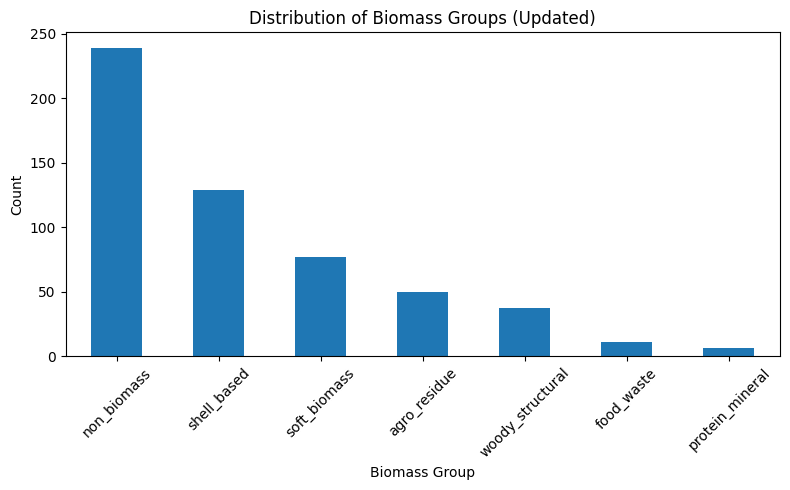

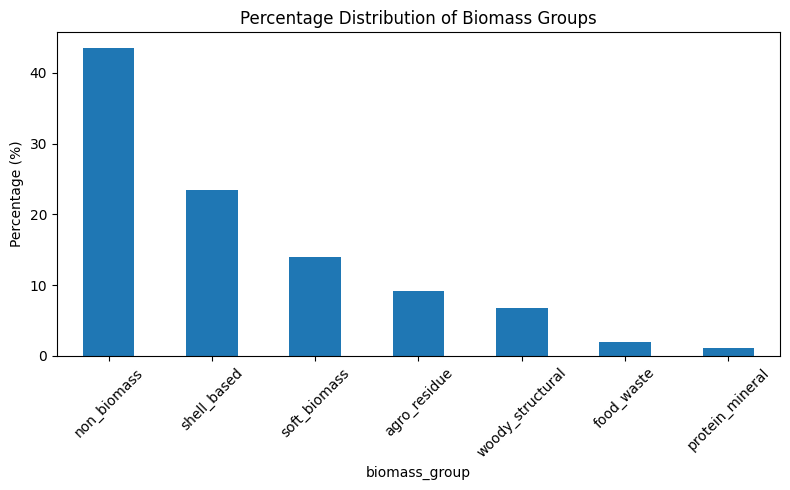

In [177]:
# ================================
# 1. Define improved grouping function
# ================================

def map_biomass_group(x):
    if pd.isna(x):
        return "non_biomass"   # ✅ correct meaning

    x = str(x).lower()

    if any(k in x for k in ["shell", "septum"]):
        return "shell_based"

    elif any(k in x for k in ["crab", "egg", "agaric", "membrane"]):
        return "protein_mineral"

    elif any(k in x for k in ["bagasse", "straw", "husk", "stalk"]):
        return "agro_residue"

    elif any(k in x for k in ["wood", "stem", "cellulose", "fiber"]):
        return "woody_structural"

    elif any(k in x for k in ["leaf", "leaves", "catkin"]):
        return "soft_biomass"

    elif any(k in x for k in ["peel", "fruit", "seed", "potato"]):
        return "food_waste"

    else:
        return "other_biomass"

# STEP 1: Recompute grouping
df["biomass_group"] = df["biomass_precursor"].apply(map_biomass_group)

df["is_biomass"] = df["biomass_precursor"].notna().astype(int)

# STEP 2: Print counts
print("Counts:\n", df["biomass_group"].value_counts())

# STEP 3: Check subset size
subset = df[df["biomass_group"] == "other_biomass"]

print("\nSubset length:", len(subset))

# STEP 4: Show top precursors
print("\nTop values:\n", subset["biomass_precursor"].value_counts().head(20))

subset = df[df["biomass_group"] == "other_biomass"]

print("Missing precursor count:", subset["biomass_precursor"].isna().sum())
print("Total rows:", len(subset))

import matplotlib.pyplot as plt

# ================================
# 1. Get counts
# ================================
counts = df["biomass_group"].value_counts()

# ================================
# 2. Print for verification
# ================================
print("Counts:\n", counts)
print("\nPercentages:\n", counts / len(df) * 100)

# ================================
# 3. Plot
# ================================
plt.figure(figsize=(8, 5))

counts.plot(kind="bar")

plt.xlabel("Biomass Group")
plt.ylabel("Count")
plt.title("Distribution of Biomass Groups (Updated)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

percent = df["biomass_group"].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))

percent.plot(kind="bar")

plt.ylabel("Percentage (%)")
plt.title("Percentage Distribution of Biomass Groups")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Understand Electrode_configuration

In [178]:
# ================================
# 1. Raw value counts
# ================================
print("Raw counts:")
print(df["electrode_configuration"].value_counts(dropna=False))


# ================================
# 2. Percentage distribution
# ================================
print("\nPercentages:")
print(df["electrode_configuration"].value_counts(normalize=True, dropna=False) * 100)


# ================================
# 3. Unique values (very important)
# ================================
print("\nUnique values:")
print(df["electrode_configuration"].unique())

Raw counts:
electrode_configuration
three-electrode    229
three_electrode    160
3-electrode        104
two_electrode       42
3_electrode         14
Name: count, dtype: int64

Percentages:
electrode_configuration
three-electrode    41.712204
three_electrode    29.143898
3-electrode        18.943534
two_electrode       7.650273
3_electrode         2.550091
Name: proportion, dtype: float64

Unique values:
<StringArray>
['three-electrode',     '3_electrode', 'three_electrode',   'two_electrode',
     '3-electrode']
Length: 5, dtype: str


Clean Electrode_config column

In [179]:
def clean_electrode_config(x):
    if pd.isna(x): 
        return "unknown"
    
    x = str(x).lower().strip().replace("_", "-")

    if "3" in x or "three" in x:
        return "three_electrode"
    elif "2" in x or "two" in x:
        return "two_electrode"
    else:
        return "other"

df["electrode_configuration"] = df["electrode_configuration"].apply(clean_electrode_config)
print(df["electrode_configuration"].value_counts())


electrode_configuration
three_electrode    507
two_electrode       42
Name: count, dtype: int64


Categorial Handling 

In [180]:
#clean material type
df["material_type"] = df["material_type"].astype(str).str.lower().str.strip()
df["material_type"] = df["material_type"].replace({
    "metal oxide": "metal_oxide",
    "metal_oxide": "metal_oxide",

    "metal sulfide": "metal_sulfide",
    "metal sulphide": "metal_sulfide",
    "metal_sulfide": "metal_sulfide",

    "carbon": "carbon",
    "composite": "composite"
})
print(df["material_type"].value_counts())

material_type
composite        349
carbon           132
metal_oxide       56
metal_sulfide     12
Name: count, dtype: int64


In [181]:

categorical_features = [
    "biomass_precursor","biomass_group","activation_agent",
    "electrolyte","electrolyte_state","material_type","electrode_configuration"
]

for col in categorical_features:
    if col in df.columns:
        df[col] = df[col].astype(str).fillna("unknown")


Flag Processing

In [182]:
flag_cols = [
    "precursor_flag",
    "substrate_flag",
    "carbonization_flag",
    "activation_agent_flag",
    "activation_temperature_flag",
    "activation_ratio_flag",
    "metal_loading_flag",
    "calcination_flag",
    "ssa_flag",
    "pv_flag",
    "pore_flag",
    "Rct_flag",
    "Rs_flag",
    "ID_IG_flag",
    "cd_flag"
]

measured_cols, applicability_cols = [], []



for col in flag_cols:
    col_lower = df[col].astype(str).str.lower()

    # 1. Applicability
    df[col.replace("_flag", "_applicable")] = col_lower.apply(
        lambda x: 0 if x == "not_applicable" else 1
    )

    # 2. Measured
    df[col.replace("_flag", "_measured")] = col_lower.apply(
        lambda x: 1 if x == "measured" else 0
    )

    measured_cols.append(col.replace("_flag", "_measured"))
    applicability_cols.append(col.replace("_flag", "_applicable"))

df = df.drop(columns=flag_cols)

In [183]:
import pandas as pd

# Reload dataset
df_new = pd.read_csv("composites.csv")

# Get flag columns
flag_cols = [
    "precursor_flag",
    "substrate_flag",
    "carbonization_flag",
    "activation_agent_flag",
    "activation_temperature_flag",
    "activation_ratio_flag",
    "metal_loading_flag",
    "calcination_flag",
    "ssa_flag",
    "pv_flag",
    "pore_flag",
    "Rct_flag",
    "Rs_flag",
    "ID_IG_flag",
    "cd_flag"
]
print("Flag columns:", flag_cols)

# Loop through all flag columns
for col in flag_cols:
    print(f"\n==== {col} ====")

    temp = df_new[[col]].copy()
    temp[col] = temp[col].astype(str).str.lower().str.strip()

    temp["applicable"] = temp[col].apply(lambda x: 0 if x == "not_applicable" else 1)
    temp["measured"] = temp[col].apply(lambda x: 1 if x == "measured" else 0)

    table = (
        temp[[col, "applicable", "measured"]]
        .drop_duplicates()
        .sort_values(by=col)
        .reset_index(drop=True)
    )

    print(table)
    

Flag columns: ['precursor_flag', 'substrate_flag', 'carbonization_flag', 'activation_agent_flag', 'activation_temperature_flag', 'activation_ratio_flag', 'metal_loading_flag', 'calcination_flag', 'ssa_flag', 'pv_flag', 'pore_flag', 'Rct_flag', 'Rs_flag', 'ID_IG_flag', 'cd_flag']

==== precursor_flag ====
   precursor_flag  applicable  measured
0        measured           1         1
1  not_applicable           0         0
2    not_measured           1         0

==== substrate_flag ====
   substrate_flag  applicable  measured
0        measured           1         1
1  not_applicable           0         0
2    not_measured           1         0

==== carbonization_flag ====
  carbonization_flag  applicable  measured
0           measured           1         1
1     not_applicable           0         0
2       not_measured           1         0

==== activation_agent_flag ====
  activation_agent_flag  applicable  measured
0              measured           1         1
1        not_applicab

EDA (TARGET DRIVEN)
everything should revolve around 
feature-->effect on capacitance

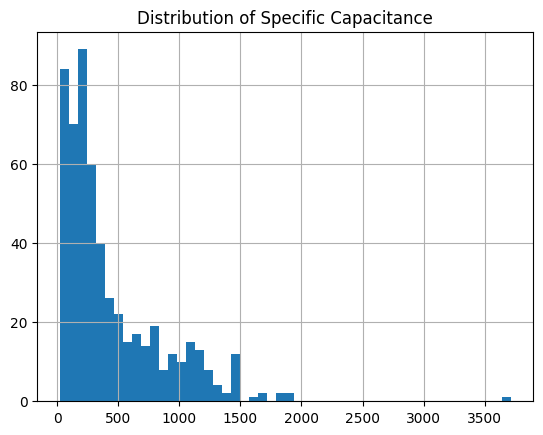

In [184]:
import matplotlib.pyplot as plt

plt.figure()
df["specific_capacitance"].hist(bins=50)
plt.title("Distribution of Specific Capacitance")
plt.show()

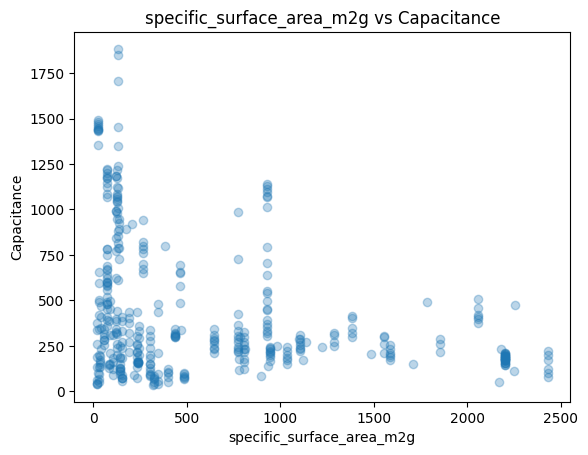

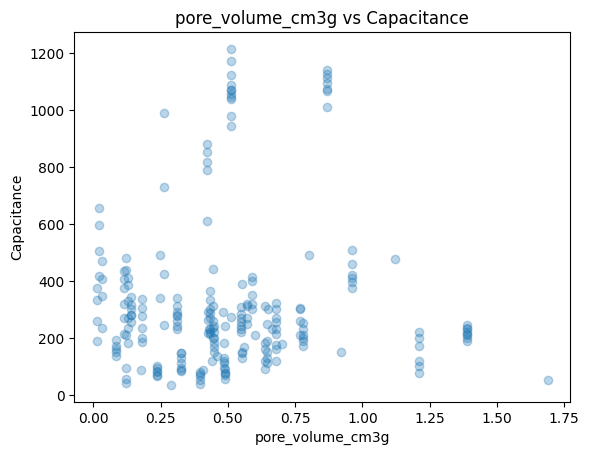

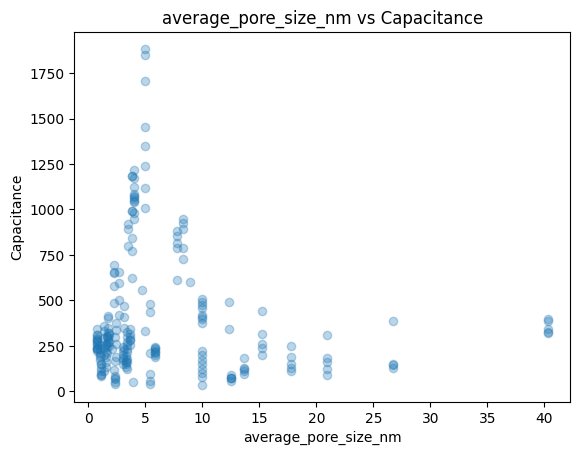

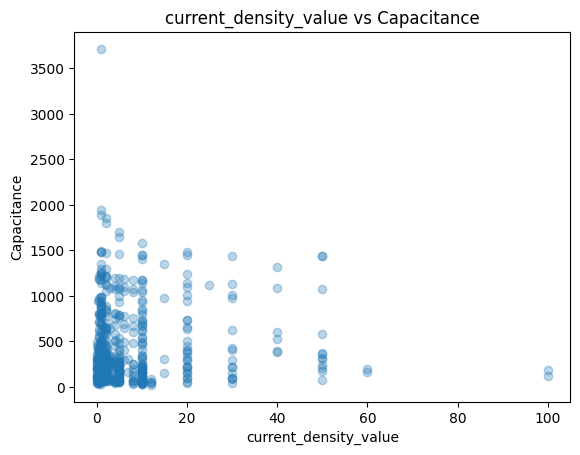

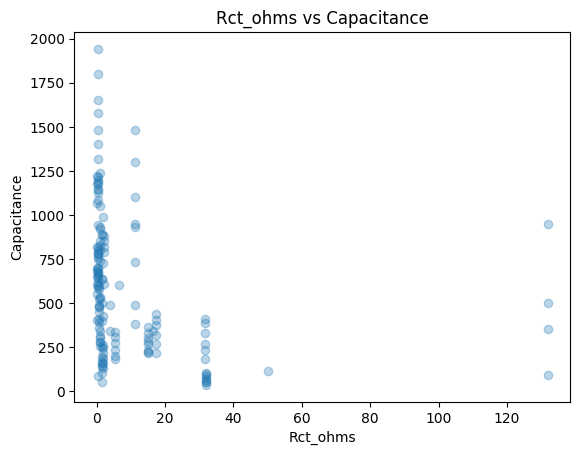

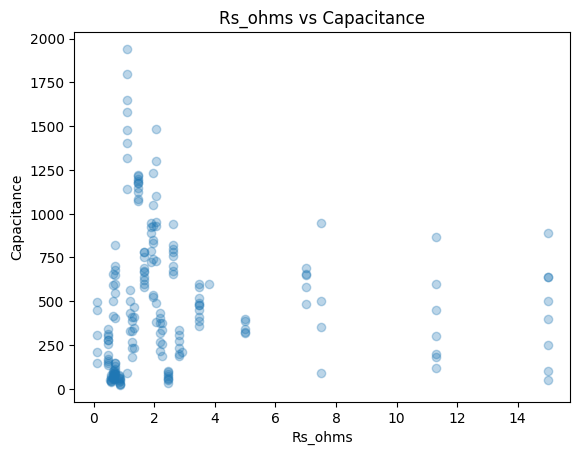

In [185]:
columns = [
    "specific_surface_area_m2g",
    "pore_volume_cm3g",
    "average_pore_size_nm",
    "current_density_value",
    "Rct_ohms",
    "Rs_ohms"
]

for col in columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

for col in columns:
    if col in df.columns:
        plt.figure()
        plt.scatter(df[col], df["specific_capacitance"], alpha=0.3)
        plt.xlabel(col)
        plt.ylabel("Capacitance")
        plt.title(f"{col} vs Capacitance")
        plt.show()

In [186]:
print("biomass_group" in df.columns)
print(df.columns.tolist())

True
['record_id', 'doi', 'material_name', 'material_type', 'device_type', 'biomass_precursor', 'carbon_substrate', 'carbonization_temperature_C', 'activation_present', 'activation_agent', 'activation_temperature_C', 'activation_ratio', 'metal_oxide_type', 'metal_loading_wt_percent', 'mass_loading_mgcm2', 'deposition_method', 'calcination_temperature_C', 'composite_structure', 'specific_surface_area_m2g', 'pore_volume_cm3g', 'average_pore_size_nm', 'electrolyte', 'electrolyte_concentration_M', 'electrolyte_state', 'electrode_configuration', 'potential_window_V', 'test_mode', 'Scan_rate_mVs', 'scan_flag', 'Rct_ohms', 'Rs_ohms', 'resistance_origin', 'resistance_linked_to_currentdensity', 'ID_IG_ratio', 'current_density_value', 'current_density_unit', 'specific_capacitance', 'capacitance_unit', 'capacitance_comparison_possible', 'rate_retention_percent', 'rate_retention_current_density', 'capacitance_retention_percent', 'cycle_test_current_density', 'cycle_life', 'cycle_test_mode', 'energ

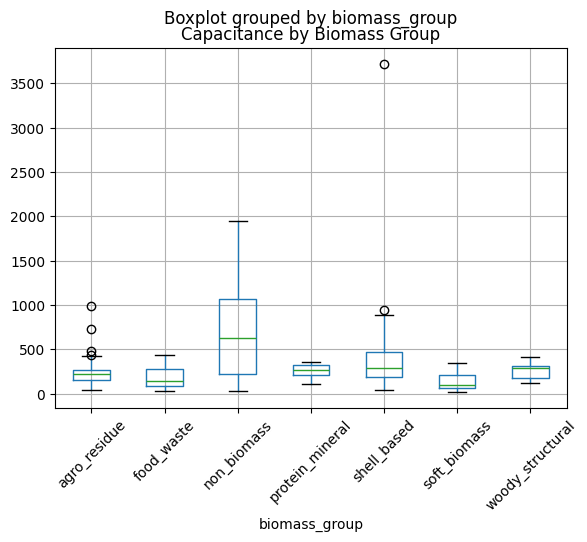

In [187]:
df.boxplot(column="specific_capacitance", by="biomass_group", rot=45)
plt.title("Capacitance by Biomass Group")
plt.show()

In [188]:
df.groupby("material_type")["specific_capacitance"].max()

material_type
carbon            375.0
composite        3713.9
metal_oxide      1482.0
metal_sulfide    1257.0
Name: specific_capacitance, dtype: float64

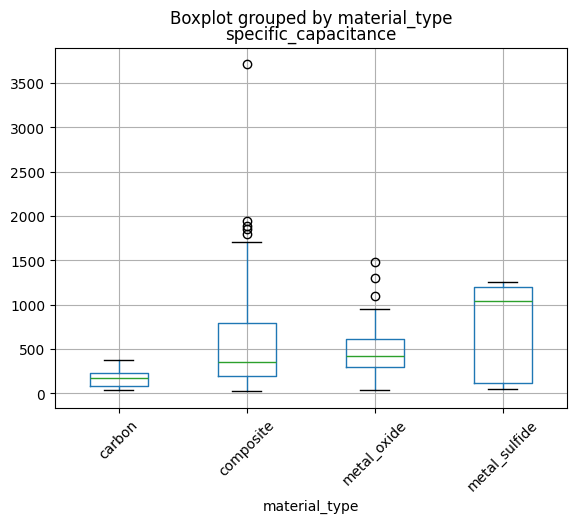

material_type
composite        349
carbon           132
metal_oxide       56
metal_sulfide     12
Name: count, dtype: int64

In [189]:

df.boxplot(column="specific_capacitance", by="material_type", rot=45)
plt.show()
df["material_type"].value_counts()

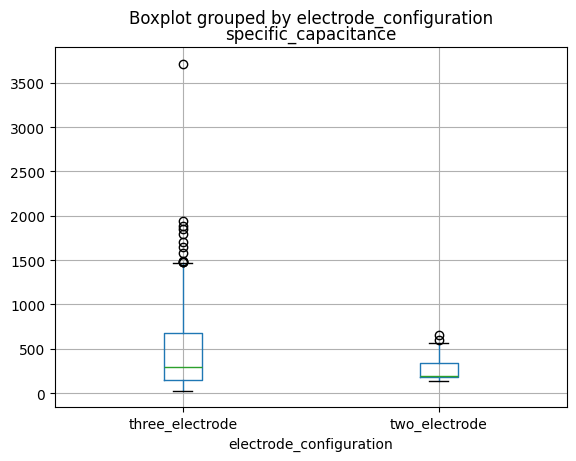

In [190]:
df.boxplot(column="specific_capacitance", by="electrode_configuration")
plt.show()

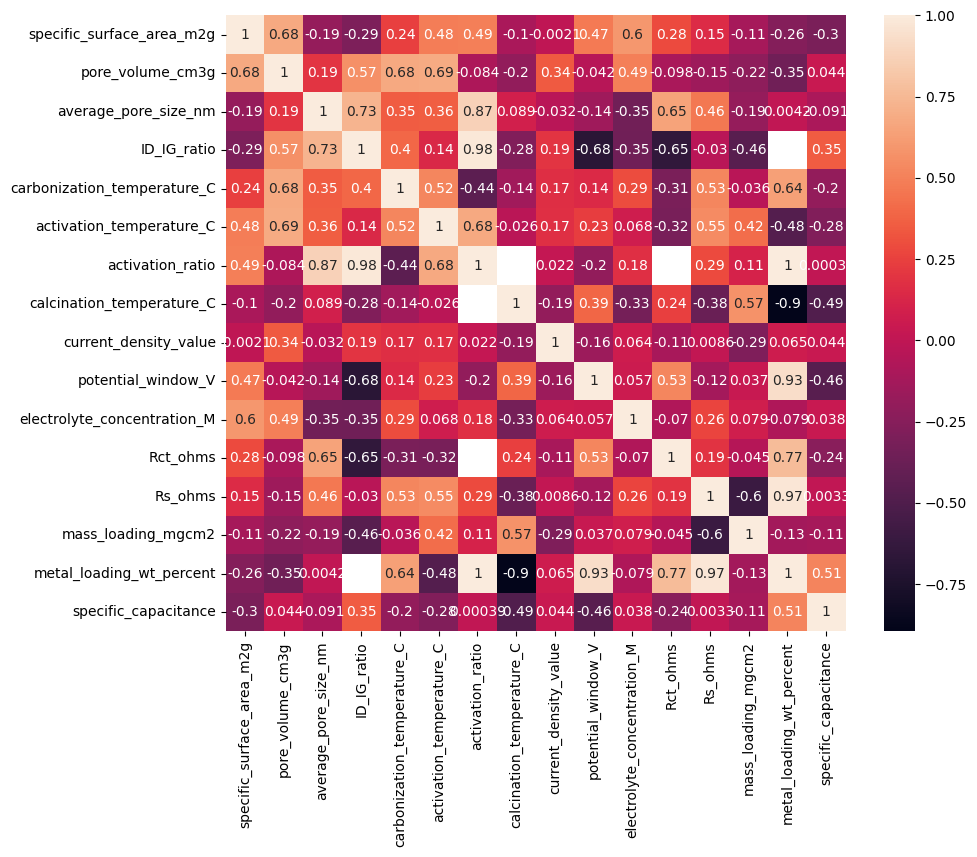

In [191]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(df[numeric_cols + ["specific_capacitance"]].corr(), annot=True)
plt.show()

In [192]:
df = df.loc[:, ~df.columns.duplicated()]
print(df.columns[df.columns.duplicated()])

Index([], dtype='str')


Feature Engineering 

In [193]:

eps = 1e-6

df["cd_log"] = np.log1p(df["current_density_value"])
df["cd_inverse"] = 1/(df["current_density_value"]+eps)
df["voltage_squared"] = df["potential_window_V"]**2


df["ssa_pore_interaction"] = df["specific_surface_area_m2g"] * df["pore_volume_cm3g"]
df["surface_to_pore_ratio"] = df["specific_surface_area_m2g"] / (df["pore_volume_cm3g"] + eps)
df["pore_efficiency"] = df["pore_volume_cm3g"]/(df["average_pore_size_nm"]+eps)

df["structural_order_proxy"] = 1/(df["ID_IG_ratio"]+eps)

df["activation_severity"] = df["activation_temperature_C"] * df["activation_ratio"]
df["activation_pore"] = df["activation_temperature_C"] * df["average_pore_size_nm"]

df["total_resistance"] = df["Rs_ohms"] + df["Rct_ohms"]
df["conductivity_index"] = 1 / (df["total_resistance"].replace(0, np.nan) + eps)

df["cd_resistance"] = df["current_density_value"] * df["total_resistance"]
df["cd_surface"] = df["current_density_value"] * df["specific_surface_area_m2g"]

df["carbonization_scaled"] = df["carbonization_temperature_C"]/1000

df["log_Rct"] = np.log1p(df["Rct_ohms"])
df["log_Rs"] = np.log1p(df["Rs_ohms"])
df["log_total_resistance"] = np.log1p(df["total_resistance"])

df["voltage_electrolyte"] = df["potential_window_V"] * df["electrolyte_concentration_M"]

df["is_three_electrode"] = df["electrode_configuration"].str.contains("3", na=False).astype(int)



STRUCTURE + REGIME

In [194]:


def extract_structure_features(x):
    x = str(x).lower()
    return pd.Series({
        "has_metal_oxide": int("oxide" in x),
        "has_sulfide": int("sulfide" in x),
        "has_graphene": int("graphene" in x),
        "has_cnt": int("cnt" in x)
    })

structure_features = df["composite_structure"].apply(extract_structure_features)

for col in structure_features.columns:
    df[col] = structure_features[col]

# MATERIAL-TYPE REGIME 

df["is_carbon"] = (df["material_type"] == "carbon").astype(int)
df["is_composite"] = (df["material_type"] == "composite").astype(int)
df["is_metal_oxide"] = (df["material_type"] == "metal_oxide").astype(int)
df["is_metal_sulfide"] = (df["material_type"] == "metal_sulfide").astype(int)

# COMBINED PSEUDOCAPACITIVE LOGIC

df["is_pseudocapacitive"] = (
    (df["is_metal_oxide"] == 1) |
    (df["is_metal_sulfide"] == 1) |
    (df["has_metal_oxide"] == 1) |
    (df["has_sulfide"] == 1)
).astype(int)


# INTERACTION FEATURES

df["ssa_carbon_effect"] = df["specific_surface_area_m2g"] * df["is_carbon"]
df["ssa_composite_effect"] = df["specific_surface_area_m2g"] * df["is_composite"]
df["ssa_oxide_effect"] = df["specific_surface_area_m2g"] * df["is_metal_oxide"]
df["ssa_sulfide_effect"] = df["specific_surface_area_m2g"] * df["is_metal_sulfide"]
df["ssa_biomass_effect"] = df["specific_surface_area_m2g"] * df["is_biomass"]
df["pore_biomass_effect"] = df["pore_volume_cm3g"] * df["is_biomass"]

df["pseudo_effect"] = df["conductivity_index"] * df["is_pseudocapacitive"]
df["resistance_composite"] = df["total_resistance"] * df["is_pseudocapacitive"]



 FINAL FEATURES


In [195]:

TARGET = "specific_capacitance"

# =========================
# NUMERICAL FEATURES
# =========================

numerical_features = [

    # --- Original physical features ---
    "specific_surface_area_m2g",
    "pore_volume_cm3g",
    "average_pore_size_nm",
    "ID_IG_ratio",
    "carbonization_temperature_C",
    "activation_temperature_C",
    "activation_ratio",
    "calcination_temperature_C",
    "current_density_value",
    "potential_window_V",
    "electrolyte_concentration_M",
    "Rct_ohms",
    "Rs_ohms",
    "metal_loading_wt_percent",
    "mass_loading_mgcm2",

    # --- Transformations ---
    "cd_log",
    "cd_inverse",
    "voltage_squared",
    "carbonization_scaled",

    # --- Resistance features ---
    "total_resistance",
    "conductivity_index",
    "log_Rct",
    "log_Rs",
    "log_total_resistance",

    # --- Structural / electrochemical ---
    "structural_order_proxy",
    "activation_severity",
    "activation_pore",

    # --- Interaction features (core physics) ---
    "ssa_pore_interaction",
    "surface_to_pore_ratio",
    "pore_efficiency",
    "cd_resistance",
    "cd_surface",
    "voltage_electrolyte",

    # --- Material regime flags ---
    "is_carbon",
    "is_composite",
    "is_metal_oxide",
    "is_metal_sulfide",
    "is_pseudocapacitive",
    "is_three_electrode",

    # --- Interaction with material types ---
    "ssa_carbon_effect",
    "ssa_composite_effect",
    "ssa_oxide_effect",
    "ssa_sulfide_effect",

    # --- Biomass interactions ---
    "ssa_biomass_effect",
    "pore_biomass_effect",

    # --- Resistance interactions ---
    "pseudo_effect",
    "resistance_composite",
]

# =========================
# ADD FLAG-DERIVED FEATURES
# =========================

numerical_features += measured_cols
numerical_features += applicability_cols


# =========================
# CATEGORICAL FEATURES
# =========================

categorical_features = [
    "biomass_group",
    "material_type",
    "electrode_configuration",
    "electrolyte",
    "electrolyte_state",
    "activation_agent"
]


# =========================
# FINAL FEATURE SET
# =========================

all_features = numerical_features + categorical_features


# =========================
# FINAL CLEANING
# =========================

# Drop rows without target
df = df.dropna(subset=[TARGET])



In [196]:
for col in categorical_features:
    print(col, df[col].nunique())

biomass_group 7
material_type 4
electrode_configuration 2
electrolyte 2
electrolyte_state 2
activation_agent 7



 GLOBAL SPLIT


In [197]:

X_full = df[all_features]
y_full = df[TARGET]

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)




 BASELINE MODELS


In [198]:


X_train_base = X_train_full.copy()
X_test_base = X_test_full.copy()

for col in X_train_base.columns:
    if X_train_base[col].dtype != "object":
        X_train_base[col] = X_train_base[col].fillna(-999)
        X_test_base[col] = X_test_base[col].fillna(-999)

X_train_num = X_train_base.select_dtypes(exclude=["object"])
X_test_num = X_test_base.select_dtypes(exclude=["object"])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_num)
X_test_scaled = scaler.transform(X_test_num)

def evaluate(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return r2_score(y_te, pred), np.sqrt(mean_squared_error(y_te, pred))

r2_lr, rmse_lr = evaluate(LinearRegression(), X_train_scaled, y_train_full, X_test_scaled, y_test_full)
r2_rf, rmse_rf = evaluate(RandomForestRegressor(n_estimators=200), X_train_num, y_train_full, X_test_num, y_test_full)
r2_xgb, rmse_xgb = evaluate(XGBRegressor(n_estimators=300), X_train_num, y_train_full, X_test_num, y_test_full)



 CATBOOST OPTIMIZED MODEL


In [199]:


cat_cols = [c for c in categorical_features if c in X_train_full.columns]
cat_idx = [X_train_full.columns.get_loc(c) for c in cat_cols]

train_pool = Pool(X_train_full, y_train_full, cat_features=cat_idx)
test_pool = Pool(X_test_full, y_test_full, cat_features=cat_idx)

model = CatBoostRegressor(
    iterations=3000,              
    depth=6,
    learning_rate=0.03,           
    l2_leaf_reg=5,                
    random_strength=1,
    bagging_temperature=1,
    border_count=128,
    
    loss_function="RMSE",
    eval_metric="R2",
    
    early_stopping_rounds=100,   
    random_seed=42,
    
    verbose=100
)

model.fit(train_pool, eval_set=test_pool, use_best_model=True)

preds = model.predict(test_pool)

r2_cat = r2_score(y_test_full, preds)
rmse_cat = np.sqrt(mean_squared_error(y_test_full, preds))

print("\nOptimized CatBoost")
print(f"R2: {r2_cat:.4f}")
print(f"RMSE: {rmse_cat:.2f}")


0:	learn: 0.0249176	test: -0.0701722	best: -0.0701722 (0)	total: 39.9ms	remaining: 1m 59s
100:	learn: 0.7491766	test: 0.7867515	best: 0.7867515 (100)	total: 4.82s	remaining: 2m 18s
200:	learn: 0.8463601	test: 0.8789659	best: 0.8789659 (200)	total: 9.83s	remaining: 2m 16s
300:	learn: 0.8856653	test: 0.9069033	best: 0.9069033 (300)	total: 14.6s	remaining: 2m 10s
400:	learn: 0.9109420	test: 0.9190701	best: 0.9193785 (398)	total: 19.5s	remaining: 2m 6s
500:	learn: 0.9271358	test: 0.9248971	best: 0.9249682 (497)	total: 24.1s	remaining: 2m
600:	learn: 0.9400620	test: 0.9311127	best: 0.9311127 (600)	total: 29s	remaining: 1m 55s
700:	learn: 0.9502424	test: 0.9348654	best: 0.9350641 (696)	total: 34.6s	remaining: 1m 53s
800:	learn: 0.9582331	test: 0.9370541	best: 0.9370640 (799)	total: 40s	remaining: 1m 49s
900:	learn: 0.9634610	test: 0.9396428	best: 0.9397299 (886)	total: 45s	remaining: 1m 44s
1000:	learn: 0.9683483	test: 0.9411151	best: 0.9411445 (992)	total: 50.4s	remaining: 1m 40s
1100:	lear



 RESULTS


In [200]:

results = pd.DataFrame({
    "Model": ["Linear","RF","XGB","CatBoost"],
    "R2": [r2_lr, r2_rf, r2_xgb, r2_cat],
    "RMSE": [rmse_lr, rmse_rf, rmse_xgb, rmse_cat]
})

print(results.sort_values(by="R2", ascending=False))


      Model        R2        RMSE
3  CatBoost  0.948205   74.024292
2       XGB  0.943130   77.566341
1        RF  0.941677   78.550915
0    Linear -1.238837  486.677657


CROSS PAPER VALIDATION

In [201]:
from sklearn.model_selection import GroupShuffleSplit

print("\n--- Group Split (DOI-wise) Evaluation ---")

groups = df["doi"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_idx, test_idx in gss.split(X_full, y_full, groups):
    X_train_g = X_full.iloc[train_idx]
    X_test_g  = X_full.iloc[test_idx]
    y_train_g = y_full.iloc[train_idx]
    y_test_g  = y_full.iloc[test_idx]
    
# Copy base preprocessing
X_train_base_g = X_train_g.copy()
X_test_base_g = X_test_g.copy()

for col in X_train_base_g.columns:
    if X_train_base_g[col].dtype != "object":
        X_train_base_g[col] = X_train_base_g[col].fillna(-999)
        X_test_base_g[col] = X_test_base_g[col].fillna(-999)

X_train_num_g = X_train_base_g.select_dtypes(exclude=["object"])
X_test_num_g = X_test_base_g.select_dtypes(exclude=["object"])

# Scaling (only for linear)
scaler_g = StandardScaler()
X_train_scaled_g = scaler_g.fit_transform(X_train_num_g)
X_test_scaled_g = scaler_g.transform(X_test_num_g)


# Linear
r2_lr_g, rmse_lr_g = evaluate(
    LinearRegression(),
    X_train_scaled_g, y_train_g,
    X_test_scaled_g, y_test_g
)

# RF
r2_rf_g, rmse_rf_g = evaluate(
    RandomForestRegressor(n_estimators=200),
    X_train_num_g, y_train_g,
    X_test_num_g, y_test_g
)

# XGB
r2_xgb_g, rmse_xgb_g = evaluate(
    XGBRegressor(n_estimators=300),
    X_train_num_g, y_train_g,
    X_test_num_g, y_test_g
)

cat_cols_g = [c for c in categorical_features if c in X_train_g.columns]
cat_idx_g = [X_train_g.columns.get_loc(c) for c in cat_cols_g]

train_pool_g = Pool(X_train_g, y_train_g, cat_features=cat_idx_g)
test_pool_g = Pool(X_test_g, y_test_g, cat_features=cat_idx_g)

model_g = CatBoostRegressor(
    iterations=3000,
    depth=6,
    learning_rate=0.03,
    l2_leaf_reg=5,
    random_strength=1,
    bagging_temperature=1,
    border_count=128,
    loss_function="RMSE",
    eval_metric="R2",
    early_stopping_rounds=100,
    random_seed=42,
    verbose=100
)

model_g.fit(train_pool_g, eval_set=test_pool_g, use_best_model=True)

preds_g = model_g.predict(test_pool_g)

r2_cat_g = r2_score(y_test_g, preds_g)
rmse_cat_g = np.sqrt(mean_squared_error(y_test_g, preds_g))

group_results = pd.DataFrame({
    "Model": ["Linear", "RF", "XGB", "CatBoost"],
    "R2": [r2_lr_g, r2_rf_g, r2_xgb_g, r2_cat_g],
    "RMSE": [rmse_lr_g, rmse_rf_g, rmse_xgb_g, rmse_cat_g]
})

print("\nGroup Split Results (DOI-wise)")
print(group_results.sort_values(by="R2", ascending=False))

train_dois = set(df.iloc[train_idx]["doi"])
test_dois = set(df.iloc[test_idx]["doi"])

print("DOI overlap:", train_dois.intersection(test_dois))


--- Group Split (DOI-wise) Evaluation ---
0:	learn: 0.0277910	test: -0.1309362	best: -0.1309362 (0)	total: 37.5ms	remaining: 1m 52s
100:	learn: 0.7650042	test: 0.1820667	best: 0.1863680 (77)	total: 4.6s	remaining: 2m 11s
200:	learn: 0.8671681	test: 0.2013934	best: 0.2072794 (168)	total: 9.11s	remaining: 2m 6s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.2072794028
bestIteration = 168

Shrink model to first 169 iterations.

Group Split Results (DOI-wise)
      Model           R2          RMSE
2       XGB     0.514184    374.627656
1        RF     0.236360    469.686462
3  CatBoost     0.207279    478.546165
0    Linear -2401.872777  26346.877809
DOI overlap: set()



FEATURE IMPORTANCE


                        feature  importance
9            potential_window_V   10.473123
17              voltage_squared    8.263249
62         precursor_applicable    4.466873
47           precursor_measured    4.028831
78                material_type    3.839677
4   carbonization_temperature_C    3.410667
7     calcination_temperature_C    3.324240
14           mass_loading_mgcm2    2.782191
32          voltage_electrolyte    2.773457
40         ssa_composite_effect    2.615660
15                       cd_log    2.560840
18         carbonization_scaled    2.535104
80                  electrolyte    2.236665
20           conductivity_index    2.021448
68     metal_loading_applicable    1.980810
64     carbonization_applicable    1.972365
8         current_density_value    1.912897
3                   ID_IG_ratio    1.892442
54         calcination_measured    1.796275
29              pore_efficiency    1.782186


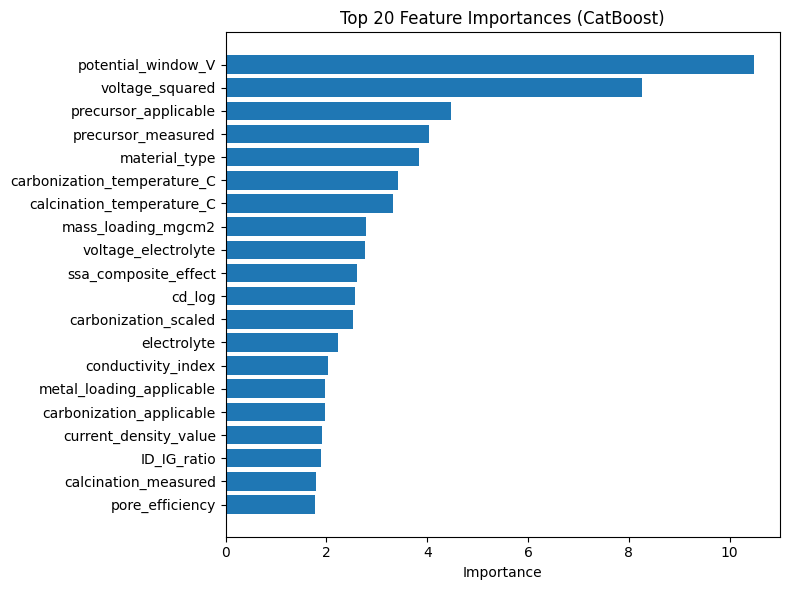

In [202]:

importances = model.get_feature_importance(train_pool)

feat_imp = pd.DataFrame({
    "feature": X_train_full.columns,
    "importance": importances
}).sort_values(by="importance", ascending=False)

print(feat_imp.head(20))


# FEATURE IMPORTANCE PLOT

import matplotlib.pyplot as plt

# Get top 20 features
top_n = 20
feat_imp_top = feat_imp.head(top_n)

plt.figure(figsize=(8, 6))
plt.barh(feat_imp_top["feature"], feat_imp_top["importance"])
plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.title(f"Top {top_n} Feature Importances (CatBoost)")

plt.tight_layout()
plt.show()



SHAP


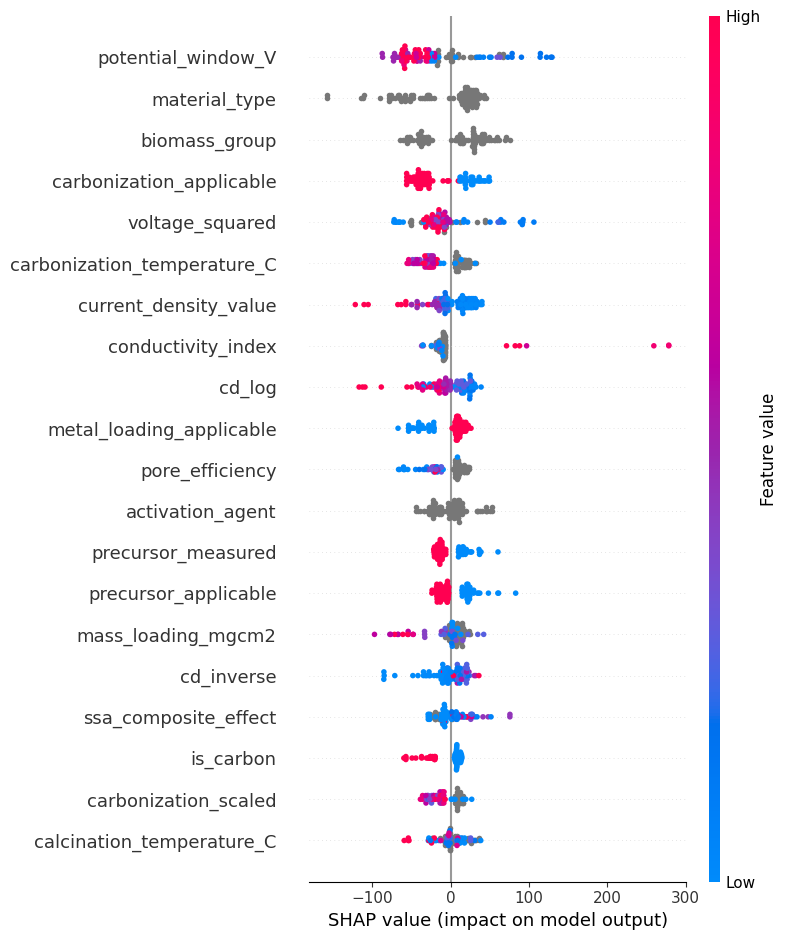

In [203]:

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_full)

shap.summary_plot(shap_values, X_test_full)




FEATURE GROUPS FOR ABLATION


In [204]:
# =========================
# BASE FEATURES (raw inputs)
# =========================

base_features = [
    "specific_surface_area_m2g",
    "pore_volume_cm3g",
    "average_pore_size_nm",
    "current_density_value",
    "potential_window_V",
    "electrolyte_concentration_M",
    "mass_loading_mgcm2",
    "metal_loading_wt_percent"
]


# =========================
# PHYSICS-INFORMED FEATURES
# =========================

physics_features = [
    "voltage_squared",
    "total_resistance",
    "conductivity_index",
    "cd_inverse",
    "cd_log",
    "cd_resistance",
    "cd_surface",
    "voltage_electrolyte"
]


# =========================
# STRUCTURAL / ELECTROCHEMICAL
# =========================

electrochem_features = [
    "Rct_ohms",
    "Rs_ohms",
    "log_Rct",
    "log_Rs",
    "log_total_resistance",
    "structural_order_proxy",
    "ID_IG_ratio",
    "activation_severity",
    "activation_pore",
    "carbonization_temperature_C",
    "activation_temperature_C",
    "activation_ratio",
    "calcination_temperature_C",
    "carbonization_scaled"
]


# =========================
# INTERACTION FEATURES
# =========================

interaction_features = [
    "ssa_pore_interaction",
    "surface_to_pore_ratio",
    "pore_efficiency",
    "ssa_biomass_effect",
    "pore_biomass_effect"
]


# =========================
# REGIME / MATERIAL BEHAVIOR
# =========================

regime_features = [
    "is_carbon",
    "is_composite",
    "is_metal_oxide",
    "is_metal_sulfide",
    "is_pseudocapacitive",
    "is_three_electrode",

    "ssa_carbon_effect",
    "ssa_composite_effect",
    "ssa_oxide_effect",
    "ssa_sulfide_effect",

    "pseudo_effect",
    "resistance_composite"
]


# =========================
# EXPERIMENTAL CONTEXT (FLAGS)
# =========================

flag_features = measured_cols + applicability_cols


# =========================
# CATEGORICAL FEATURES
# =========================

categorical_feats = categorical_features
feature_sets = {

    "Base":
        base_features,

    "Base + Physics":
        base_features + physics_features,

    "Base + Physics + Electrochemical":
        base_features + physics_features + electrochem_features,

    "Base + Physics + Electrochemical + Interaction":
        base_features + physics_features + electrochem_features + interaction_features,

    "Base + Physics + Electrochemical + Interaction + Regime":
        base_features + physics_features + electrochem_features + interaction_features + regime_features,

    "Full Model (All Features)":
        base_features + physics_features + electrochem_features + interaction_features + regime_features + flag_features + categorical_feats
}

IMPLEMENT ABLATION

In [205]:

results_ablation = []
# ================================
# GLOBAL SPLIT (USE EVERYWHERE)
# ================================

X_full = df[all_features]
y_full = df[TARGET]

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)

for name, feats in feature_sets.items():
    
    print(f"\n===== {name} =====")
    
    X_train = X_train_full[feats]
    X_test = X_test_full[feats]
    y_train = y_train_full
    y_test = y_test_full
    # Identify categorical columns present in this subset
    cat_cols = [c for c in feats if c in categorical_features]
    cat_idx = [X_train.columns.get_loc(c) for c in cat_cols]
    
    train_pool = Pool(X_train, y_train, cat_features=cat_idx)
    test_pool = Pool(X_test, y_test, cat_features=cat_idx)
    
    model = CatBoostRegressor(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        verbose=0,
        random_seed=42
    )
    
    model.fit(train_pool, eval_set=test_pool)
    
    preds = model.predict(test_pool)
    
    r2 = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    
    print(f"R2: {r2:.4f}, RMSE: {rmse:.2f}")
    
    results_ablation.append([name, r2, rmse])

#ablation results 
ablation_df = pd.DataFrame(results_ablation, columns=["Model", "R2", "RMSE"])

print("\nAblation Results:")
print(ablation_df.sort_values(by="R2", ascending=False))






===== Base =====
R2: 0.5734, RMSE: 212.44

===== Base + Physics =====
R2: 0.7764, RMSE: 153.80

===== Base + Physics + Electrochemical =====
R2: 0.9005, RMSE: 102.62

===== Base + Physics + Electrochemical + Interaction =====
R2: 0.8891, RMSE: 108.31

===== Base + Physics + Electrochemical + Interaction + Regime =====
R2: 0.9398, RMSE: 79.82

===== Full Model (All Features) =====
R2: 0.9389, RMSE: 80.39

Ablation Results:
                                               Model        R2        RMSE
4  Base + Physics + Electrochemical + Interaction...  0.939778   79.819550
5                          Full Model (All Features)  0.938911   80.391912
2                   Base + Physics + Electrochemical  0.900450  102.624246
3     Base + Physics + Electrochemical + Interaction  0.889109  108.312403
1                                     Base + Physics  0.776412  153.799471
0                                               Base  0.573391  212.444356
